In [4]:
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

# RefEdit-Bench Agent Evaluation

Runs the MMEdit agent on RefEdit-Bench annotations. The benchmark has no target image reference; this notebook loads the source image and local object/reference geometry, then saves edited outputs, trajectories, raw agent steps, and timings for qualitative review.

Install with `uv sync --extra models --extra benchmark`. By default this notebook reads `~/Datasets/MMEdit/refedit-bench/annotations.jsonl`; override it with `MMEDIT_REFEDIT_ANNOTATIONS` or edit the path below. Configure `MMEDIT_API_KEY` or `GOOGLE_API_KEY`. Start with a few annotation indices, inspect outputs and trajectories, then expand. HF image references use original split row indices.

In [5]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from within the MMEdit repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from evaluation.common import HFImageLoader, annotate_sample, load_sample, read_jsonl, run_benchmark, select_reference_prompts

BENCHMARK = 'refedit_bench'
RANDOM_SEED = 42
ANNOTATION_FILE = Path(os.environ.get('MMEDIT_REFEDIT_ANNOTATIONS', '~/Datasets/MMEdit/refedit-bench/annotations.jsonl')).expanduser().resolve()
OUTPUT_DIR = Path(os.environ.get('MMEDIT_REFEDIT_OUTPUT_DIR', str(PROJECT_ROOT / 'outputs/evaluation' / BENCHMARK))).expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not ANNOTATION_FILE.is_file():
    raise FileNotFoundError(f'RefEdit-Bench JSONL not found: {ANNOTATION_FILE}. Set MMEDIT_REFEDIT_ANNOTATIONS.')
records = list(read_jsonl(ANNOTATION_FILE))
if not records:
    raise ValueError(f'No annotations found in {ANNOTATION_FILE}')
image_loader = HFImageLoader()
print(f'{len(records)} RefEdit-Bench annotations loaded from {ANNOTATION_FILE}')
print('Fields:', sorted(records[0]))

200 RefEdit-Bench annotations loaded from /Users/nghialt3670/Datasets/MMEdit/refedit-bench/annotations.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


easy:000 Change the color of the boat with bicycles and people to white.
Reference selectors: [{'token': '<v1>', 'refers_to': 'the boat with bicycles and people', 'box': [40, 218, 365, 299], 'point': [87.5, 263.5], 'scribble': True}]


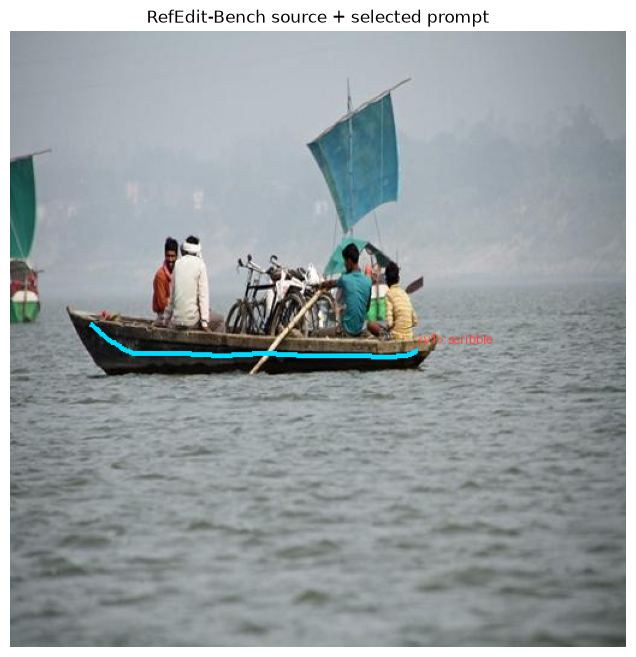

In [3]:
SAMPLE_INDEX = 0
record = records[SAMPLE_INDEX]
sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader)
if not sample['instruction']:
    raise ValueError('RefEdit-Bench record has no instruction/prompt/edit_instruction/task field.')
print(sample['sample_id'], sample['instruction'])
print('Reference selectors:', [{'token': r['token'], 'refers_to': r['span'], 'box': r['bbox_xyxy'], 'point': r['point_xy'], 'scribble': bool(r['scribble_strokes'])} for r in sample['references']])

select_reference_prompts(sample, seed=RANDOM_SEED)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(annotate_sample(sample)); ax.set_title('RefEdit-Bench source + selected prompt')
ax.axis('off'); plt.show()

In [4]:
from smolagents import OpenAIModel
from tools import image_editing_tools

MODEL_ID = os.environ.get('MMEDIT_MODEL_ID', 'gemini-2.5-flash')
API_BASE = os.environ.get('MMEDIT_OPENAI_BASE_URL', 'https://generativelanguage.googleapis.com/v1beta/openai/')
API_KEY = os.environ.get('MMEDIT_API_KEY') or os.environ.get('GOOGLE_API_KEY')
if not API_KEY: raise EnvironmentError('Set MMEDIT_API_KEY or GOOGLE_API_KEY.')
llm = OpenAIModel(model_id=MODEL_ID, api_base=API_BASE, api_key=API_KEY, temperature=0)
tools = image_editing_tools()
print('RefEdit-Bench agent ready:', MODEL_ID)

RefEdit-Bench agent ready: gemini-2.5-flash


In [7]:
# Annotation positions are distinct from the original HF dataset row indices in hf:// references.
# Run the full annotation set. To run a subset, replace this with e.g. range(10) or [0, 5, 12].
SAMPLE_INDICES = range(len(records))
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    output_dir=OUTPUT_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    seed=RANDOM_SEED,
    display_fn=None,
)
print('Output directory:', OUTPUT_DIR)
print(f'Processed {len(benchmark_results)} RefEdit-Bench samples.')
print('RefEdit-Bench has no target image; evaluate the saved outputs against the benchmark protocol.')

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ {"type": "user_message", "text": "Make the quilt on the bottom part of the bunk bed black.", "objects":         │
│ ["image_0", "box_0"]}                                                                                           │
│                                                                                                                 │
╰─ OpenAIModel - gemini-2.5-flash ────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  mask_0 = segment_object(image_0, box=box_0)                                                                      
  image_1 = edit_object(image_0, mask_0, prompt='Make the quilt black', mode='local')                              
  send_message(text='Here is the quilt on the bottom bunk bed in black.', objects=[image_1])                       
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

100%|██████████| 4/4 [00:00<00:00, 86.27it/s]


Final answer: {'text': 'Here is the quilt on the bottom bunk bed in black.', 'objects': [<PIL.Image.Image image 
mode=RGB size=512x512 at 0x822FAFD90>]}

[Step 1: Duration 24.20 seconds| Input tokens: 2,230 | Output tokens: 146]

easy:002 completed 29.83 seconds
Saved run summary: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/outputs/debug/refedit_bench/results/results.jsonl
Output directory: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/outputs/debug/refedit_bench
Processed 1 RefEdit-Bench samples.
RefEdit-Bench has no target image; evaluate the saved outputs against the benchmark protocol.


In [6]:
completed = [r for r in benchmark_results if r['status'] == 'completed']
failed = [r for r in benchmark_results if r['status'] == 'failed']
print(f'RefEdit-Bench samples: {len(benchmark_results)} | completed: {len(completed)} | failed: {len(failed)}')
if benchmark_results: print(f"Mean runtime: {sum(r['elapsed_seconds'] for r in benchmark_results)/len(benchmark_results):.2f}s")
print('Review saved output images and trajectories; runtime/status are not image-quality scores.')

RefEdit-Bench samples: 4 | completed: 4 | failed: 0
Mean runtime: 28.82s
Review saved output images and trajectories; runtime/status are not image-quality scores.


## Modified VIEScore (optional)

Scores already-saved output images using RefEdit's original `metadata.edit_instruction_single` and GT polygon masks, with identical tight source/output crops (zero padding). It discovers outputs from `results/images/*_output.png` as well as `results/results.jsonl`, so you can run this cell without rerunning the agent even if a later subset run replaced the summary JSONL.

Install VIEScore and its dependencies from [Step1X-Edit](https://github.com/stepfun-ai/Step1X-Edit). Set `VIESCORE_ROOT` to that checkout's `GEdit-Bench` directory and `VIESCORE_KEY_PATH` to a local file containing only the OpenAI API key on its first line. The evaluator explicitly requests the `gpt-4o` API model. It saves resumable per-sample SC/PQ/O results and summarizes Easy and Hard separately.

In [ ]:
from evaluation.refedit_viescore import evaluate_saved_refedit_outputs

metric_rows, score_summary = evaluate_saved_refedit_outputs(
    records,
    output_dir=OUTPUT_DIR,
    image_loader=image_loader,
)
display([{'category': category, **metrics} for category, metrics in score_summary.items()])